# Retrieval on robot data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/2_models/03_retrieval.ipynb) &nbsp; Guide note: [guide-retrieval](https://www.matthewwnuk.com/guide-retrieval.html)

Retrieval answers a question by finding the nearest items in a collection. Here the collection is 1,516
robot camera frames with CLIP embeddings. The notebook finds frames of the same task, scores the ranking
five ways against a trivial baseline, searches with text, and looks at what approximate search and
compression cost.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import time, numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from guide_utils import data, style
style.use()
f = data.libero_frames(); E, thumbs, ep, task = f["clip"], f["thumbs"], f["episode"], f["task"]      # embeddings are unit length
P = f["pixels"] - f["pixels"].mean(1, keepdims=True); P /= np.linalg.norm(P, axis=1, keepdims=True)    # the baseline: 256 grey pixels
print(E.shape, np.linalg.norm(E, axis=1)[:3].round(3))

(1516, 512) [1. 1. 1.]


## Nearest neighbours

With unit-length vectors, similarity is a dot product. A frame must not retrieve itself or other frames
of its own episode, which are near-copies.

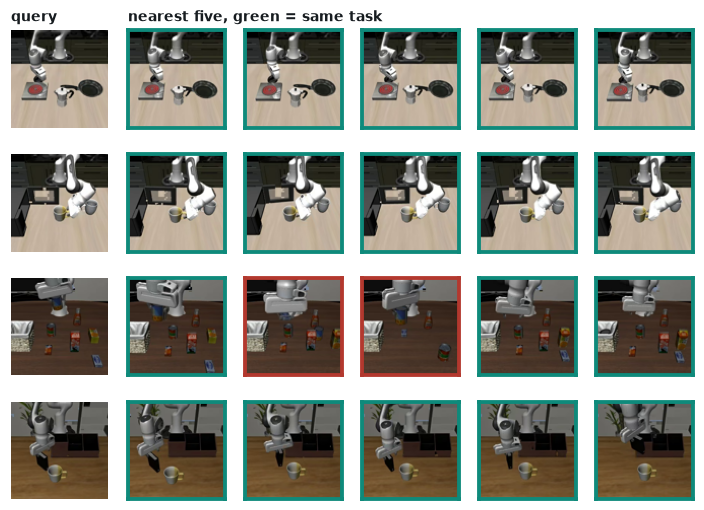

In [3]:
def rank(F_):
    S = F_ @ F_.T; S[ep[:, None] == ep[None, :]] = -9; return np.argsort(-S, 1)
order = rank(E); relevant = task[order] == task[:, None]
qs = [np.flatnonzero(task == t)[5] for t in (3, 2, 5, 9)]; fig, ax = plt.subplots(4, 6, figsize=(8, 5.6))
for r, q in enumerate(qs):
    ax[r, 0].imshow(thumbs[q]); style.bare(ax[r, 0])
    for c in range(5):
        a = ax[r, c + 1]; a.imshow(thumbs[order[q, c]]); style.bare(a)
        for s in a.spines.values(): s.set_visible(True); s.set_color(style.TEAL if relevant[q, c] else style.RED); s.set_linewidth(2.5)
ax[0, 0].set_title("query", fontsize=9); ax[0, 1].set_title("nearest five, green = same task", fontsize=9, loc="left"); plt.show()

## Scoring a ranking

- **Recall at k**: is at least one relevant item in the top k?
- **Precision at k**: what share of the top k is relevant?
- **Mean reciprocal rank**: 1 / (rank of the first relevant item), averaged.
- **Mean average precision**: rewards ranking all the relevant items near the top.

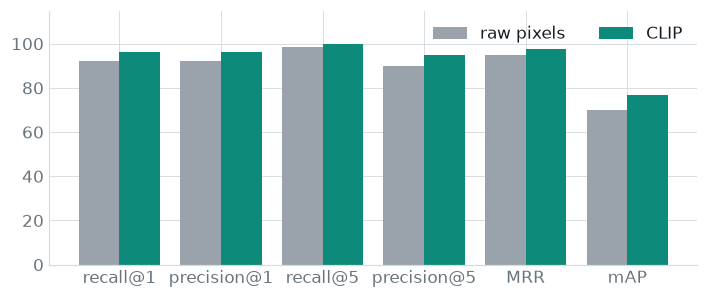

recall@1     pixels 0.921   CLIP 0.962
precision@1  pixels 0.921   CLIP 0.962
recall@5     pixels 0.984   CLIP 0.998
precision@5  pixels 0.897   CLIP 0.949
MRR          pixels 0.949   CLIP 0.978
mAP          pixels 0.698   CLIP 0.768


In [4]:
def metrics(F_):
    order = rank(F_); rel = task[order] == task[:, None]; valid = ep[order] != ep[:, None]; out = {}
    for k in (1, 5): out[f"recall@{k}"] = rel[:, :k].any(1).mean(); out[f"precision@{k}"] = rel[:, :k].mean()
    out["MRR"] = (1 / (rel.argmax(1) + 1)).mean(); ap = []
    for i in range(len(F_)):
        r = rel[i][valid[i]]; hits = np.cumsum(r); ap.append((hits[r] / (np.flatnonzero(r) + 1)).mean())
    out["mAP"] = np.mean(ap); return out
mc, mp = metrics(E), metrics(P); x = np.arange(len(mc)); plt.figure(figsize=(7.6, 3))
plt.bar(x - 0.2, [v * 100 for v in mp.values()], 0.4, label="raw pixels", color=style.GREY); plt.bar(x + 0.2, [v * 100 for v in mc.values()], 0.4, label="CLIP", color=style.TEAL)
plt.xticks(x, mc.keys()); plt.ylim(0, 115); plt.legend(ncol=2); plt.show()
for k in mc: print(f"{k:12s} pixels {mp[k]:.3f}   CLIP {mc[k]:.3f}")

CLIP is better, and the pixel baseline is close behind. These scenes differ so much in overall
appearance that almost anything can tell the tasks apart. Always score the trivial method.

## Searching with text

CLIP's text encoder puts sentences in the same space, so a sentence can query the frames. The text
embeddings for six queries were computed in advance.

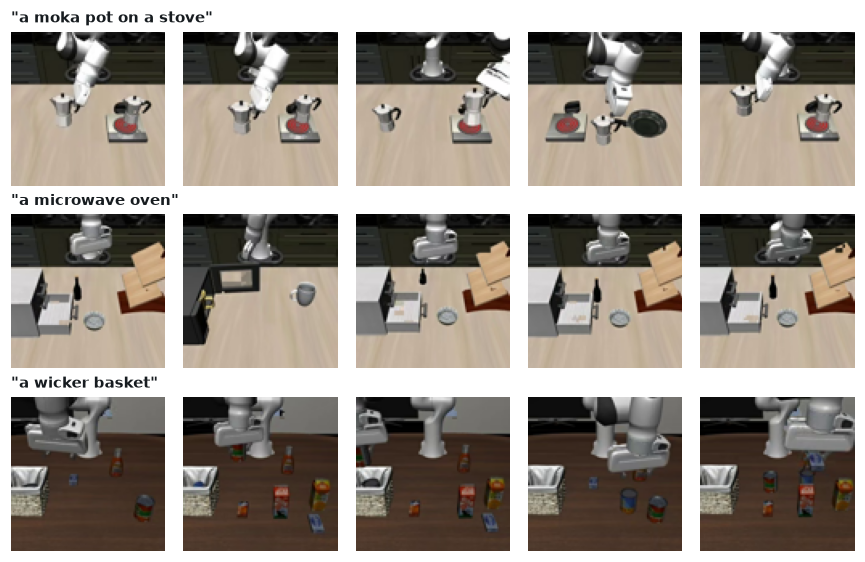

In [5]:
T = f["text_clip"]; S = T @ E.T; fig, ax = plt.subplots(3, 5, figsize=(8, 5.2))
for r, qi in enumerate((0, 1, 2)):
    top, seen = [], set()
    for j in np.argsort(-S[qi]):
        if ep[j] not in seen: top.append(j); seen.add(ep[j])
        if len(top) == 5: break
    for c, j in enumerate(top): ax[r, c].imshow(thumbs[j]); style.bare(ax[r, c])
    ax[r, 0].set_title(f"\"{f['text_queries'][qi]}\"", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## Approximate search

Exact search compares the query with everything. An inverted-file index clusters the collection ahead of
time and searches only the clusters nearest the query.

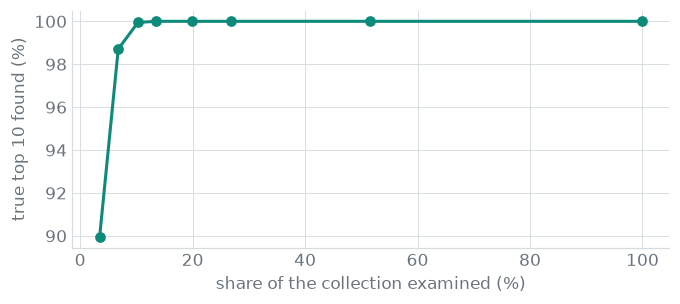

[(1, '3% examined', '90% found'), (2, '7% examined', '99% found'), (3, '10% examined', '100% found'), (4, '13% examined', '100% found')]


In [6]:
km = KMeans(32, n_init=3, random_state=0).fit(E); cluster = km.labels_; C = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)
S = E @ E.T; np.fill_diagonal(S, -9); truth = np.argsort(-S, 1)[:, :10]; nprobes = [1, 2, 3, 4, 6, 8, 16, 32]; frac_seen, found = [], []
for nprobe in nprobes:
    probe = np.argsort(-(E @ C.T), 1)[:, :nprobe]; rec, fr = [], []
    for i in range(0, len(E), 4):
        cand = np.flatnonzero(np.isin(cluster, probe[i])); cand = cand[cand != i]; top = cand[np.argsort(-(E[cand] @ E[i]))[:10]]
        rec.append(len(set(top) & set(truth[i])) / 10); fr.append(len(cand) / len(E))
    frac_seen.append(np.mean(fr) * 100); found.append(np.mean(rec) * 100)
plt.figure(figsize=(7, 2.8)); plt.plot(frac_seen, found, marker="o"); plt.xlabel("share of the collection examined (%)"); plt.ylabel("true top 10 found (%)"); plt.show()
print([(n, f"{a:.0f}% examined", f"{b:.0f}% found") for n, a, b in zip(nprobes, frac_seen, found)][:4])

## Compressing the vectors

Memory is what limits large indexes. Store each number in 8 bits, or keep only its sign.

In [7]:
def recall10(stored):
    S2 = E @ stored.T; np.fill_diagonal(S2, -9); got = np.argsort(-S2, 1)[:, :10]; return np.mean([len(set(a) & set(b)) / 10 for a, b in zip(got, truth)]) * 100
lo, hi = E.min(), E.max(); q8 = np.round((E - lo) / (hi - lo) * 255) / 255 * (hi - lo) + lo; sign = np.sign(E) / np.sqrt(E.shape[1])
print(f"32-bit floats: {E.shape[1] * 4} bytes, 100%\n8-bit integers: {E.shape[1]} bytes, {recall10(q8):.0f}%\n1 bit per number: {E.shape[1] // 8} bytes, {recall10(sign):.0f}%")

32-bit floats: 2048 bytes, 100%
8-bit integers: 512 bytes, 91%
1 bit per number: 64 bytes, 69%


## Things to try

- Make the relevance stricter: same task *and* same stage of the episode (`f["frac"]`). What happens to each metric?
- Re-rank CLIP's top 20 by pixel similarity. Does a second opinion help?
- Time exact search on random vectors as the collection grows to a million. Where would an index pay off?